In [ ]:
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
import numpy as np
from sklearn.model_selection import train_test_split

In [ ]:
df = yf.download("BTC-USD")

/tmp/ipykernel_534/1552046255.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("BTC-USD")
[*********************100%***********************]  1 of 1 completed


In [ ]:
df

Price,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,
2026-07-14,64956.113281,65046.132812,62207.523438,62238.585938,29841287318
2026-07-15,64712.375000,65507.593750,64442.820312,64959.808594,27029791676
2026-07-16,63789.281250,64931.855469,63701.804688,64713.296875,27232426674
2026-07-17,63899.460938,64332.019531,62489.453125,63789.910156,27280236800
2026-07-18,64796.601562,64816.503906,63845.015625,63899.179688,14162542470
2026-07-19,64690.804688,64909.886719,64250.914062,64799.277344,15000653941
2026-07-20,65230.027344,65735.718750,63720.390625,64684.417969,30988932408
2026-07-21,66505.125000,66910.062500,65113.656250,65228.871094,29554470321


In [ ]:
df.reset_index(inplace=True)

In [ ]:
df = df[["Date", "Close"]]

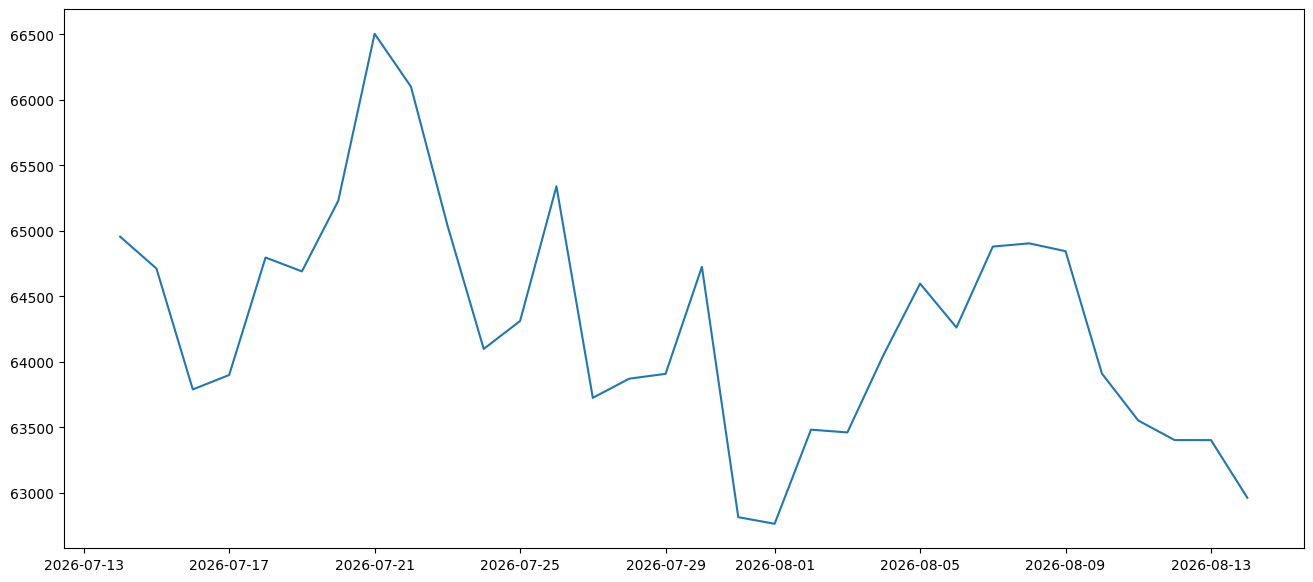

In [ ]:
plt.figure(figsize=(16,7))
plt.plot(df["Date"], df["Close"])

In [ ]:
df["Close"] = (df["Close"] - df["Close"].mean()) / df["Close"].std()

/tmp/ipykernel_534/851527108.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Close"] = (df["Close"] - df["Close"].mean()) / df["Close"].std()


In [ ]:
df["Close"]

Ticker,BTC-USD
0,0.765197
1,0.488834
2,-0.557819
3,-0.432891
4,0.584335
5,0.464376
6,1.075776
7,2.521550
8,2.063101
9,0.865769


In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_val = train_test_split(df["Close"], test_size=0.2, shuffle=False)
x_val, x_test = train_test_split(x_val, test_size=0.4, shuffle=False)

In [ ]:
x_train

Ticker,BTC-USD
0,0.765197
1,0.488834
2,-0.557819
3,-0.432891
4,0.584335
5,0.464376
6,1.075776
7,2.521550
8,2.063101
9,0.865769


In [ ]:
x_val

Ticker,BTC-USD
25,0.706888
26,0.639083
27,-0.420277
28,-0.827003


In [ ]:
x_test

Ticker,BTC-USD
29,-0.996448
30,-0.996744
31,-1.496003


In [ ]:
window_size = 20
batch_size =32
shuffle_buffer = x_train.shape[0]

In [ ]:
def window_ds(series, window_size, batch_size, shuffle_buffer):
    ds= tf.data.Dataset.from_tensor_slices(series)
    ds = ds.window(window_size + 1, shift=1, drop_remainder=True)
    ds = ds.flat_map(lambda w: w.batch(window_size +1))
    ds = ds.shuffle(shuffle_buffer).map(lambda w: (w[:-1], w[-1]))
    ds= ds.batch(batch_size).prefetch(1)
    return ds

In [ ]:
x_train_ds = window_ds(x_train, window_size,batch_size, shuffle_buffer)
x_val_ds = window_ds(x_train, window_size,batch_size, x_val.shape[0])

In [ ]:
for i in x_train_ds:
    print(i)

(<tf.Tensor: shape=(5, 20, 1), dtype=float64, numpy=
array([[[ 0.5843345 ],
        [ 0.46437636],
        [ 1.0757758 ],
        [ 2.52154961],
        [ 2.06310079],
        [ 0.86576932],
        [-0.20721475],
        [ 0.03465478],
        [ 1.20080971],
        [-0.63081973],
        [-0.46475007],
        [-0.42301895],
        [ 0.50349873],
        [-1.66393291],
        [-1.72110835],
        [-0.90623094],
        [-0.93015702],
        [-0.25545224],
        [ 0.35858252],
        [-0.02169685]],

       [[-0.43289144],
        [ 0.5843345 ],
        [ 0.46437636],
        [ 1.0757758 ],
        [ 2.52154961],
        [ 2.06310079],
        [ 0.86576932],
        [-0.20721475],
        [ 0.03465478],
        [ 1.20080971],
        [-0.63081973],
        [-0.46475007],
        [-0.42301895],
        [ 0.50349873],
        [-1.66393291],
        [-1.72110835],
        [-0.90623094],
        [-0.93015702],
        [-0.25545224],
        [ 0.35858252]],

       [[-0.55781906],


In [ ]:
input_layer = tf.keras.layers.Input(shape=[window_size])
l0 = tf.keras.layers.Dense(128, activation="relu")(input_layer)
l1 = tf.keras.layers.Dense(256, activation="relu")(l0)
output_l = tf.keras.layers.Dense(1)(l1)

model = tf.keras.models.Model(inputs=input_layer, outputs=output_l)

In [ ]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,969 (140.50 KB)

 Trainable params: 35,969 (140.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer="RMSprop",
             loss="mse",
             metrics=["mse"])

In [ ]:
model.fit(x_train_ds, validation_data=x_val_ds, epochs=100)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - loss: 0.2414 - mse: 0.2414 - val_loss: 0.1334 - val_mse: 0.1334


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.1334 - mse: 0.1334 - val_loss: 0.3718 - val_mse: 0.3718
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 0.3718 - mse: 0.3718 - val_loss: 0.0952 - val_mse: 0.0952
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - loss: 0.0952 - mse: 0.0952 - val_loss: 0.0156 - val_mse: 0.0156
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - loss: 0.0156 - mse: 0.0156 - val_loss: 0.0025 - val_mse: 0.0025
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - loss: 0.0025 - mse: 0.0025 - val_loss: 5.6318e-04 - val_mse: 5.6318e-04
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 5.6318e-04 - mse: 5.6318e-04 - val_loss: 1.5708e-04 - val_mse: 1.5708e-04
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - loss: 1.5708e-04 - mse: 1.5708e-04 - val_loss: 4.9900e-05 - val_mse: 4.9900e-05
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - loss: 4.9900e-05 - mse: 4.9900e-05 - val_loss: 1.8245e-05 - val_mse: 1.8245e-05
Epoch 10/100
1/1

In [ ]:
x_test = x_test.to_numpy()

In [ ]:
forecast = []
buys = {}
sells = {}

for i in range(0, len(x_test) - window_size, window_size):
    f = model.predict(x_test[i:i+window_size][np.newaxis])[0][0]

    if f > x_test[window_size]:
        buys.update({i+window_size:x_test[i+window_size]})
    elif f < x_test[window_size]:
        sells.update({i+window_size:x_test[i+window_size]})


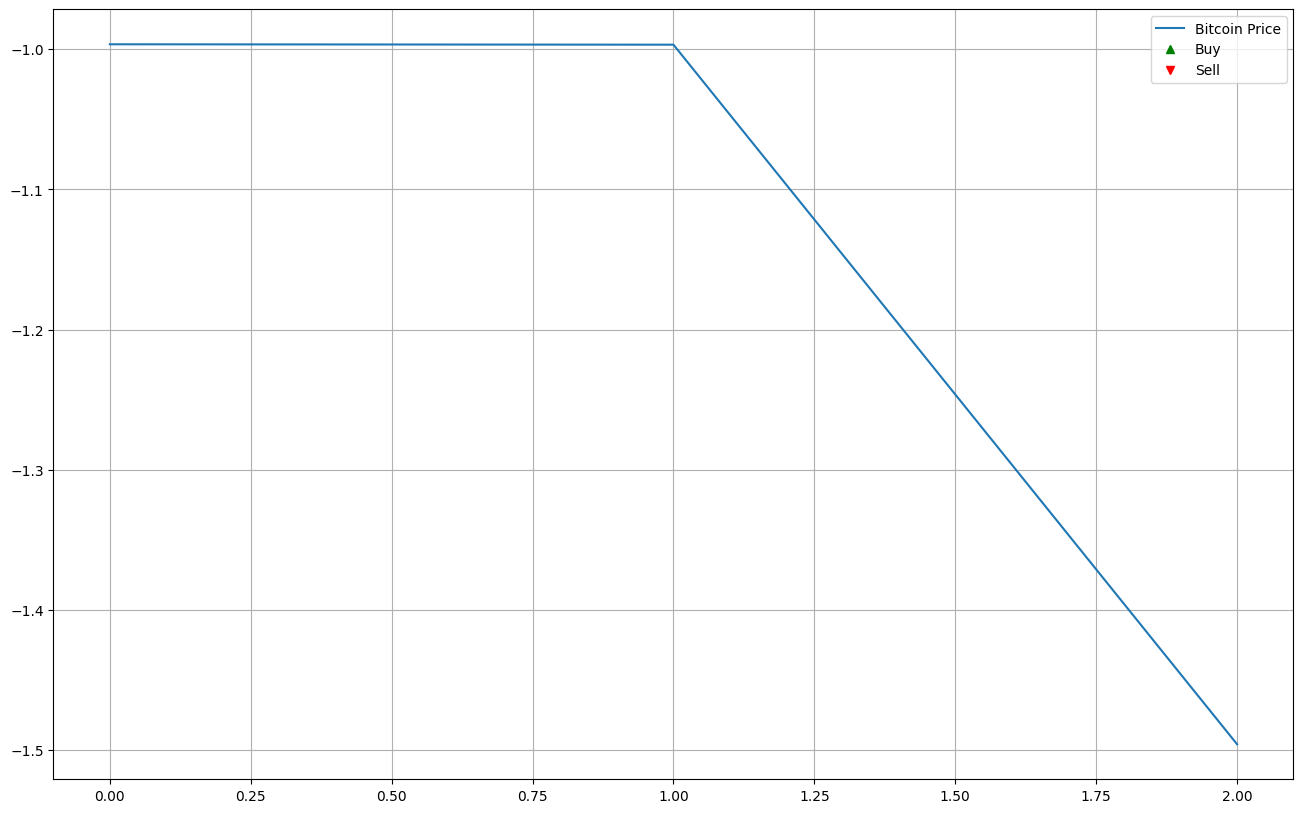

In [ ]:
plt.figure(figsize=(16, 10))
plt.plot(x_test, label="Bitcoin Price")
plt.plot(forecast, label="")
plt.plot(list(buys.keys()), list(buys.values()), "^", color="g", label="Buy")
plt.plot(list(sells.keys()), list(sells.values()), "v", color="r", label="Sell")
plt.legend()
plt.grid(True)
